In [1]:
%%capture
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
productivity_ds= fetch_ucirepo(id=597)

X = productivity_ds.data.features.drop(columns=["date"])
y = productivity_ds.data.targets

In [3]:
display(X.sample(5))
display(y.sample(5))

,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers
732,Quarter2,sweing,Thursday,2,0.80,22.52,1327.0,0,113,0.0,0,0,57.5
631,Quarter1,sweing,Thursday,6,0.70,18.79,766.0,2760,30,0.0,0,0,33.0
60,Quarter1,finishing,Sunday,11,0.75,4.15,NaN,960,0,0.0,0,0,8.0
1094,Quarter1,sweing,Saturday,11,0.80,11.41,471.0,3420,50,0.0,0,0,58.0
815,Quarter3,finishing,Tuesday,4,0.75,5.13,NaN,960,0,0.0,0,0,8.0


,actual_productivity
445,0.800352
574,0.561979
585,0.950186
1153,0.894444
382,0.670216


In [4]:
y.isna().sum()

,0
actual_productivity,0


In [5]:
cat_cols_names=X.select_dtypes("object").columns.to_list()
X[cat_cols_names]=X.loc[:,cat_cols_names].astype("category")

In [6]:
onehot=OneHotEncoder(sparse_output=False).set_output(transform="pandas")
encoded_columns=onehot.fit_transform(X[cat_cols_names])

In [7]:
X=pd.concat([encoded_columns,X.drop(columns=cat_cols_names)],axis=1)
X["wip"]=X["wip"].fillna(X["wip"].mean()).copy()
X.sample(5)

,quarter_Quarter1,quarter_Quarter2,quarter_Quarter3,quarter_Quarter4,quarter_Quarter5,department_finishing,department_sweing,day_Monday,day_Saturday,day_Sunday,...,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers
476,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,11,0.50,48.18,1282.0,6480,23,0.0,0,0,54.0
336,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,12,0.35,15.26,1111.0,6120,23,0.0,0,0,34.0
350,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,7,0.35,22.94,1450.0,10080,30,0.0,0,0,56.0
347,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,5,0.70,20.40,1352.0,10260,50,0.0,0,0,57.0
517,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,7,0.65,23.54,830.0,6600,0,0.0,0,0,55.0


In [8]:
def split_to_cls(x):
    if x <= 0.5:
        return 0
    elif 0.5 < x <= 0.8:
        return 1
    else:
        return 2

In [9]:
y_cls_target=y["actual_productivity"].apply(split_to_cls)

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
X,
y_cls_target,
test_size=0.2,
stratify=y_cls_target
)


In [22]:
model=DecisionTreeClassifier(
    criterion='gini',
    max_depth=25,
    class_weight='balanced'
    )

In [23]:
model.fit(X_train,y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=25)

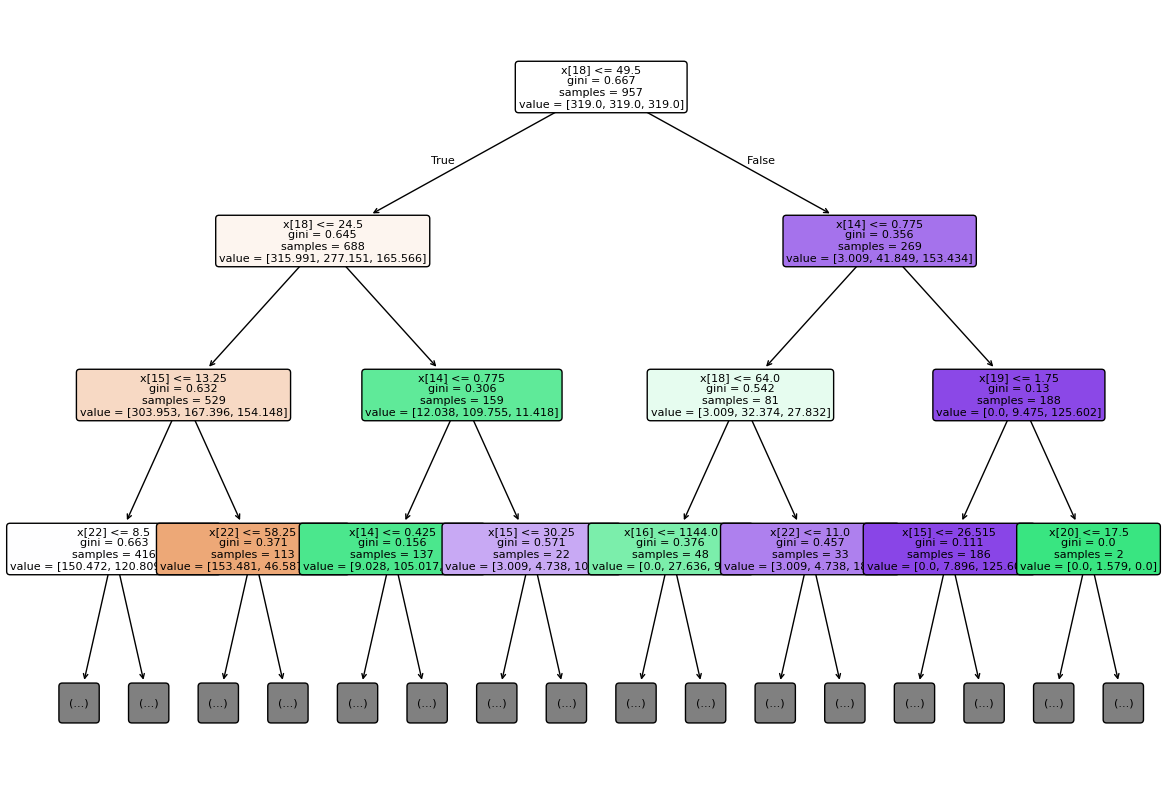

In [24]:
plt.figure(figsize=(12, 8))
plot_tree(
    decision_tree=model,
    max_depth = 3,
    rounded = True,
    filled = True,
    fontsize = 8
)
plt.tight_layout()
plt.show()

In [25]:
y_preds = model.predict(X_test)
print(classification_report(y_test, y_preds))

              precision    recall  f1-score   support

           0       0.44      0.44      0.44        27
           1       0.68      0.74      0.71       101
           2       0.82      0.75      0.79       112

    accuracy                           0.71       240
   macro avg       0.65      0.65      0.65       240
weighted avg       0.72      0.71      0.71       240



In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay,roc_auc_score,roc_curve

In [28]:
cm=confusion_matrix(y_test, y_preds)
cm

array([[12, 12,  3],
       [11, 75, 15],
       [ 4, 24, 84]])

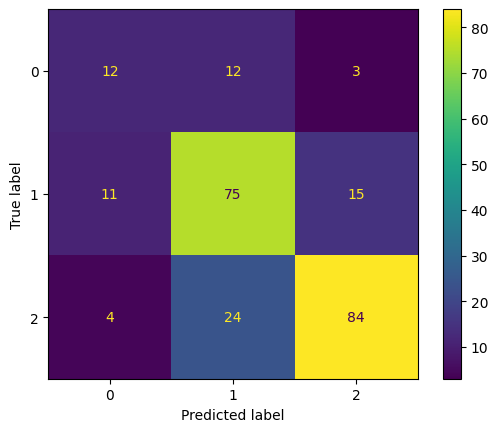

In [30]:
display=ConfusionMatrixDisplay(confusion_matrix=cm)
display.plot()
plt.show()

In [82]:
model2=DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=60,
    min_samples_leaf=10,
  #  max_leaf_nodes = 10,
  #   min_impurity_decrease=0.06,
    random_state=42
)

In [83]:
model2.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=20, min_samples_leaf=10, min_samples_split=60,
                       random_state=42)

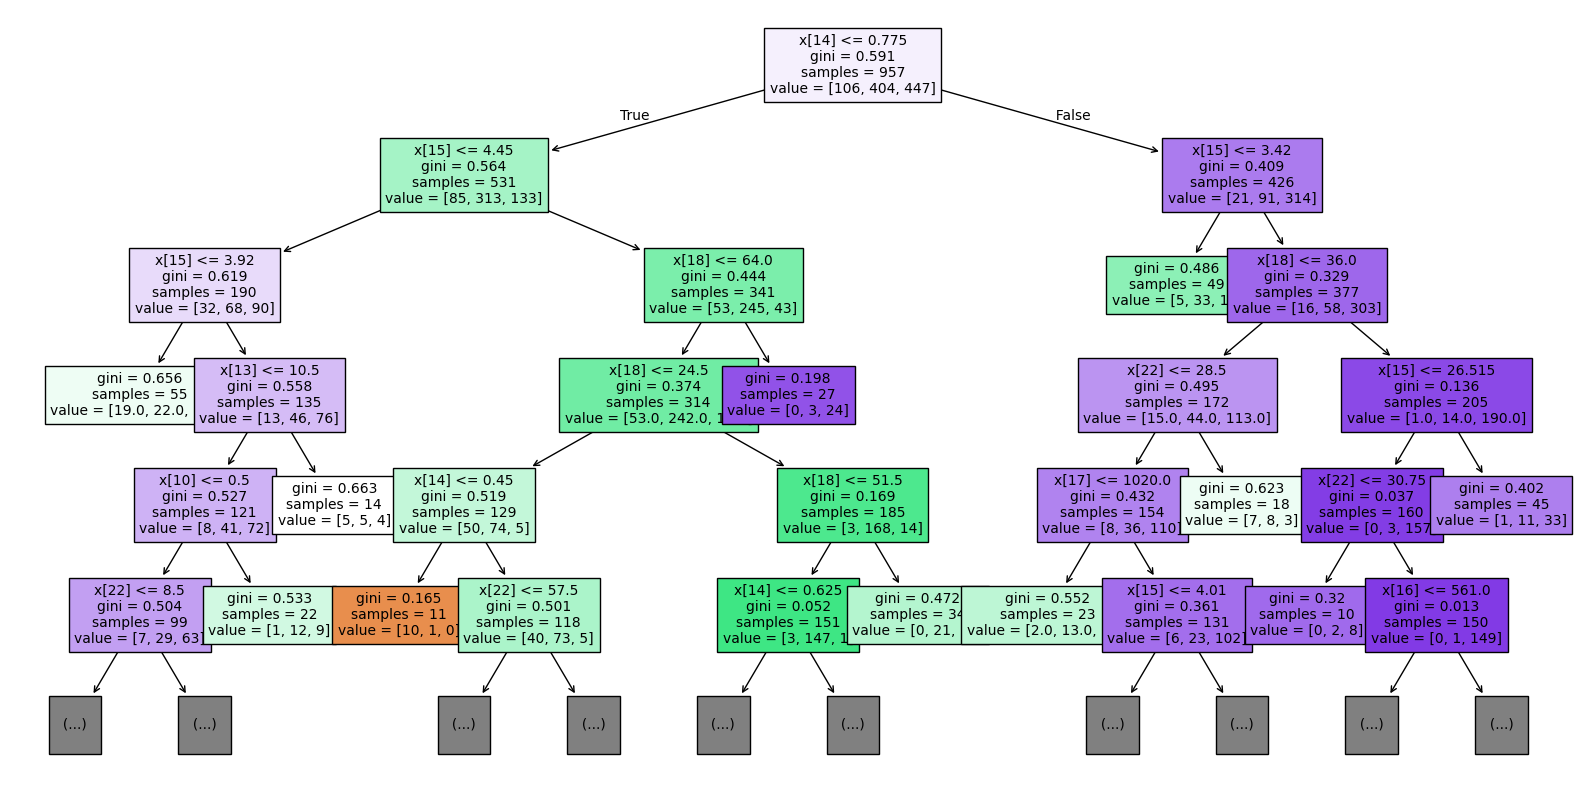

In [84]:
plt.figure(figsize=(16,8))
plot_tree(
    decision_tree=model2,
    max_depth=5,
    filled=True,
    fontsize=10
)
plt.tight_layout()
plt.show()

In [85]:
 model2.cost_complexity_pruning_path(X_train,y_train)

{'ccp_alphas': array([0.        , 0.00015856, 0.00019505, 0.00073232, 0.00094207,
        0.00108543, 0.00175368, 0.00238634, 0.00414323, 0.00436277,
        0.00636444, 0.00656268, 0.00693268, 0.00770956, 0.00777753,
        0.01121582, 0.01994611, 0.02759793, 0.02986995, 0.03200212,
        0.09640642]),
 'impurities': array([0.31407061, 0.31422917, 0.31442422, 0.31515654, 0.31609861,
        0.31718404, 0.31893772, 0.32609675, 0.33023998, 0.33896551,
        0.34532995, 0.35189264, 0.35882532, 0.36653488, 0.3743124 ,
        0.38552822, 0.40547434, 0.43307226, 0.46294222, 0.49494434,
        0.59135076])}